# One protein, six EMBL-EBI resources: following the cross-references

**Module 01 · my implementation** — Seid Adem

The introductory lecture says that EMBL-EBI's resources *"cross-reference each other"*. This notebook checks that claim
with code. Starting from a single UniProt accession, **P00533 (human EGFR)** (the drug target analysed in
[02.1](../../02_accessing_and_handling_data/01_apis_and_data_collection/implementation/02_chembl_egfr_ic50.ipynb)), it
follows each cross-reference to the linked resource's own API and asks two questions:

1. **Does the link resolve, and does the other resource link back?**
2. **Do the resources agree?** (structure lists, sequences, gene models)

| Resource | Kind | What it adds for EGFR |
|----------|------|----------------------|
| UniProtKB | curated knowledgebase | function, sequence, domain map, and the links below |
| PDBe | archive + added value (SIFTS mappings) | experimental 3-D structures, mapped residue-by-residue to UniProt |
| AlphaFold DB | predicted structures | a model for every residue, with per-residue confidence (pLDDT) |
| ChEMBL | curated bioactivity | compounds tested against EGFR |
| Ensembl | genome annotation | the gene, its location and transcripts |
| Europe PMC | literature | articles that mention the accession |

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from dsls.ebi_api import EBIClient, chembl, uniprot

FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
ACCESSION = "P00533"
results = []  # one row per resource for the summary table


def record(resource, kind, found, fact, check):
    results.append(
        {"resource": resource, "kind": kind, "record": found, "key fact": fact, "cross-check": check}
    )

## 1 · Start in UniProt

In [2]:
up = uniprot()
resp = up.get(f"uniprotkb/{ACCESSION}.json")  # headers are case-insensitive
entry = resp.json()
release = resp.headers.get("X-UniProt-Release", "?")
seq = entry["sequence"]["value"]
xrefs = pd.DataFrame(
    [
        {"database": x["database"], "id": x["id"], **{p["key"]: p["value"] for p in x.get("properties", [])}}
        for x in entry["uniProtKBCrossReferences"]
    ]
)
features = pd.DataFrame(
    [
        {
            "type": f["type"],
            "description": f.get("description", ""),
            "start": f["location"]["start"]["value"],
            "end": f["location"]["end"]["value"],
        }
        for f in entry["features"]
        if f["type"] in {"Signal", "Transmembrane", "Domain"}
    ]
)
print(
    f"UniProt release {release}: {entry['uniProtkbId']}, {len(seq)} aa, "
    f"{xrefs['database'].nunique()} linked databases, {len(xrefs)} cross-references"
)
links = xrefs[xrefs["database"].isin(["PDB", "AlphaFoldDB", "ChEMBL", "Ensembl"])]
links["database"].value_counts().to_frame("links from UniProt")

UniProt release 2026_04: EGFR_HUMAN, 1210 aa, 103 linked databases, 783 cross-references


,links from UniProt
database,
PDB,388
Ensembl,4
AlphaFoldDB,1
ChEMBL,1


## 2 · PDBe: experimental structures

PDBe's SIFTS service maps each PDB chain to UniProt residue ranges. The question is whether UniProt's list of PDB entries
is the same as PDBe's list of structures mapped to P00533.

In [3]:
pdbe = EBIClient("https://www.ebi.ac.uk/pdbe/api", "pdbe")
chains = pd.DataFrame(pdbe.get_json(f"mappings/best_structures/{ACCESSION}")[ACCESSION])
pdbe_ids = set(chains["pdb_id"].str.lower())
uniprot_ids = set(xrefs.loc[xrefs["database"] == "PDB", "id"].str.lower())
both, only_pdbe, only_up = pdbe_ids & uniprot_ids, pdbe_ids - uniprot_ids, uniprot_ids - pdbe_ids
print(
    f"PDBe: {len(chains)} chains in {len(pdbe_ids)} entries; UniProt lists {len(uniprot_ids)} entries; "
    f"shared {len(both)}, only in PDBe {len(only_pdbe)}, only in UniProt {len(only_up)}"
)
print("Only in PDBe (sample):", sorted(only_pdbe)[:8])
methods = chains.drop_duplicates("pdb_id")["experimental_method"].value_counts()
xray = chains.drop_duplicates("pdb_id").query("experimental_method == 'X-ray diffraction'")["resolution"]
record(
    "PDBe",
    "structures (archive + SIFTS)",
    f"{len(pdbe_ids)} entries",
    f"{methods.to_dict()}; median X-ray resolution {xray.median():.2f} Å",
    f"{len(both)} shared with UniProt, {len(only_pdbe)} PDBe-only, {len(only_up)} UniProt-only",
)
methods.to_frame("entries")

PDBe: 654 chains in 394 entries; UniProt lists 388 entries; shared 388, only in PDBe 6, only in UniProt 0
Only in PDBe (sample): ['9ntp', '9pwi', '9vox', '9voy', '9voz', '9wr8']


,entries
experimental_method,
X-ray diffraction,370
Electron Microscopy,18
Solution NMR,6


## 3 · AlphaFold DB: predicted structure and confidence

AlphaFold DB models every UniProt sequence. Two checks: whether the model was built on **the same sequence** as the current
UniProt entry, and how per-residue confidence (pLDDT, 0–100) varies along the protein.

In [4]:
af = EBIClient("https://alphafold.ebi.ac.uk", "alphafold")
models = pd.DataFrame(af.get_json(f"api/prediction/{ACCESSION}"))
canonical = models[models["uniprotAccession"] == ACCESSION].iloc[0]
same_sequence = canonical["uniprotSequence"] == seq
conf = af.get_json(canonical["plddtDocUrl"].replace("https://alphafold.ebi.ac.uk/", ""))
plddt = pd.Series(conf["confidenceScore"], index=conf["residueNumber"], name="pLDDT")
print(f"{len(models)} models: {models['entryId'].tolist()} (canonical + isoforms)")
print(
    f"canonical model {canonical['entryId']} (v{canonical['latestVersion']}): mean pLDDT {canonical['globalMetricValue']:.1f}; "
    f"sequence identical to current UniProt entry: {same_sequence}"
)
record(
    "AlphaFold DB",
    "predicted structures",
    f"{len(models)} models (canonical + isoforms)",
    f"mean pLDDT {canonical['globalMetricValue']:.1f}; {canonical['fractionPlddtVeryHigh']:.0%} of residues > 90",
    f"model sequence identical to UniProt: {same_sequence}",
)

4 models: ['AF-P00533-F1', 'AF-P00533-4-F1', 'AF-P00533-3-F1', 'AF-P00533-2-F1'] (canonical + isoforms)
canonical model AF-P00533-F1 (v6): mean pLDDT 75.9; sequence identical to current UniProt entry: True


## 4 · ChEMBL: from protein to bioactivity, and back

In [5]:
ch = chembl()
targets = ch.get_json(
    "chembl/api/data/target.json",
    {"target_components__accession": ACCESSION, "target_type": "SINGLE PROTEIN"},
)["targets"]
uniprot_chembl = xrefs.loc[xrefs["database"] == "ChEMBL", "id"].tolist()
target_id = targets[0]["target_chembl_id"]
# Same request as the 02.1 EGFR notebook (an unfiltered count of all activities times out on ChEMBL's side)
ic50 = {"target_chembl_id": target_id, "standard_type": "IC50", "pchembl_value__isnull": "false"}
n_act = ch.get_json("chembl/api/data/activity.json", {**ic50, "limit": 1})["page_meta"]["total_count"]
status = ch.get_json("chembl/api/data/status.json")
print(
    f"UniProt → ChEMBL: {uniprot_chembl}; ChEMBL → UniProt {ACCESSION}: {[t['target_chembl_id'] for t in targets]}"
)
record(
    "ChEMBL",
    "curated bioactivity",
    target_id,
    f"{n_act:,} IC50 records with a pChEMBL value ({status['chembl_db_version']}; analysed in 02.1)",
    f"link is reciprocal: {uniprot_chembl == [target_id]}",
)

UniProt → ChEMBL: ['CHEMBL203']; ChEMBL → UniProt P00533: ['CHEMBL203']


## 5 · Ensembl: the gene behind the protein

In [6]:
ens_xrefs = xrefs[xrefs["database"] == "Ensembl"]
gene_ids = sorted({g.split(".")[0] for g in ens_xrefs["GeneId"]})
ensembl = EBIClient("https://rest.ensembl.org", "ensembl")
gene = ensembl.get_json(f"lookup/id/{gene_ids[0]}", {"expand": 1, "content-type": "application/json"})
coding = [t for t in gene["Transcript"] if t.get("biotype") == "protein_coding"]
up_tx = {t.split(".")[0] for t in ens_xrefs["id"]}
ens_tx = {t["id"] for t in gene["Transcript"]}
print(
    f"{gene['display_name']} ({gene['id']}): chromosome {gene['seq_region_name']}:{gene['start']:,}-{gene['end']:,} "
    f"({gene['strand']:+d} strand), {len(gene['Transcript'])} transcripts ({len(coding)} protein-coding), "
    f"assembly {gene['assembly_name']}"
)
record(
    "Ensembl",
    "genome annotation",
    gene["id"],
    f"chr{gene['seq_region_name']}, {len(gene['Transcript'])} transcripts ({len(coding)} protein-coding)",
    f"all {len(up_tx)} UniProt-linked transcripts exist in Ensembl: {up_tx <= ens_tx}",
)

EGFR (ENSG00000146648): chromosome 7:55,018,820-55,211,628 (+1 strand), 23 transcripts (16 protein-coding), assembly GRCh38


## 6 · Europe PMC: the literature

In [7]:
epmc = EBIClient("https://www.ebi.ac.uk/europepmc/webservices/rest", "europepmc")
hits = epmc.get_json(
    "search",
    {"query": f"ACCESSION_ID:{ACCESSION} AND ACCESSION_TYPE:uniprot", "format": "json", "pageSize": 1},
)["hitCount"]
record(
    "Europe PMC",
    "literature",
    f"{hits:,} articles",
    "full-text articles that cite the accession P00533",
    "text-mined link (one-way)",
)
record(
    "UniProtKB",
    "curated knowledgebase",
    f"{ACCESSION} ({release})",
    f"{len(seq)} aa; {xrefs['database'].nunique()} linked databases",
    "starting point",
)
summary = (
    pd.DataFrame(results)
    .set_index("resource")
    .loc[["UniProtKB", "PDBe", "AlphaFold DB", "ChEMBL", "Ensembl", "Europe PMC"]]
)
summary

,kind,record,key fact,cross-check
resource,,,,
UniProtKB,curated knowledgebase,P00533 (2026_04),1210 aa; 103 linked databases,starting point
PDBe,structures (archive + SIFTS),394 entries,"{'X-ray diffraction': 370, 'Electron Microscop...","388 shared with UniProt, 6 PDBe-only, 0 UniPro..."
AlphaFold DB,predicted structures,4 models (canonical + isoforms),mean pLDDT 75.9; 47% of residues > 90,model sequence identical to UniProt: True
ChEMBL,curated bioactivity,CHEMBL203,"19,378 IC50 records with a pChEMBL value (ChEM...",link is reciprocal: True
Ensembl,genome annotation,ENSG00000146648,"chr7, 23 transcripts (16 protein-coding)",all 4 UniProt-linked transcripts exist in Ense...
Europe PMC,literature,638 articles,full-text articles that cite the accession P00533,text-mined link (one-way)


## 7 · Experiment vs prediction along the sequence

For each residue: how many PDB chains have it inside their **mapped UniProt range** (from the PDBe mappings), and
AlphaFold's confidence, drawn over UniProt's domain map. A mapped range describes the construct, not the residues that were
actually resolved, so full-length cryo-EM constructs "cover" disordered regions they don't resolve. The number of
**high-resolution X-ray chains** is plotted separately as a stricter measure.

,median chains (mapped range),median X-ray chains ≤ 2.5 Å,mean pLDDT
extracellular (25-645),58.0,4.0,91.0
kinase domain (712-979),553.0,282.0,84.0
C-terminal tail (1001-1210),12.0,0.0,32.0


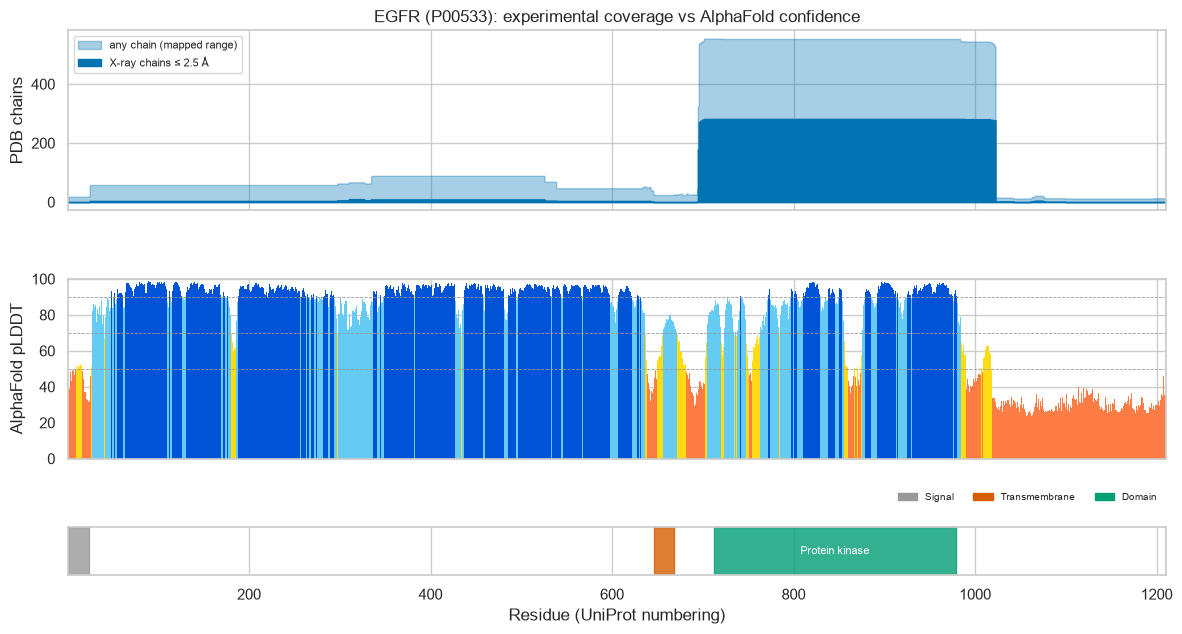

In [8]:
def per_residue(rows):
    counts = np.zeros(len(seq) + 1, dtype=int)
    for s, e in zip(rows["unp_start"], rows["unp_end"], strict=True):
        counts[s : e + 1] += 1
    return pd.Series(counts[1:], index=range(1, len(seq) + 1))


cov = per_residue(chains)
xray_cov = per_residue(chains.query("experimental_method == 'X-ray diffraction' and resolution <= 2.5"))

fig, axes = plt.subplots(3, 1, figsize=(12, 6.5), sharex=True, gridspec_kw={"height_ratios": [3, 3, 0.8]})
axes[0].fill_between(
    cov.index,
    cov.values,
    step="mid",
    color=sns.color_palette("colorblind")[0],
    alpha=0.35,
    label="any chain (mapped range)",
)
axes[0].fill_between(
    xray_cov.index,
    xray_cov.values,
    step="mid",
    color=sns.color_palette("colorblind")[0],
    label="X-ray chains ≤ 2.5 Å",
)
axes[0].legend(fontsize=8, loc="upper left")
axes[0].set(ylabel="PDB chains", title=f"EGFR ({ACCESSION}): experimental coverage vs AlphaFold confidence")
colors = pd.cut(plddt, [0, 50, 70, 90, 100], labels=["#FF7D45", "#FFDB13", "#65CBF3", "#0053D6"]).astype(str)
axes[1].bar(plddt.index, plddt.values, width=1.0, color=colors, linewidth=0)
axes[1].set(ylabel="AlphaFold pLDDT", ylim=(0, 100))
for y in (50, 70, 90):
    axes[1].axhline(y, color="0.6", lw=0.6, ls="--")
palette = {"Signal": "0.6", "Transmembrane": "#D55E00", "Domain": "#009E73"}
for kind, colour in palette.items():
    axes[2].axvspan(0, 0, color=colour, label=kind)  # legend entries
axes[2].legend(fontsize=7, ncol=3, loc="upper right", bbox_to_anchor=(1, 1.9), frameon=False)
for _, f in features.iterrows():
    axes[2].axvspan(f["start"], f["end"], color=palette[f["type"]], alpha=0.8)
    label = f["description"] or f["type"]
    if f["end"] - f["start"] > 60:
        axes[2].text(
            (f["start"] + f["end"]) / 2, 0.5, label, ha="center", va="center", fontsize=8, color="white"
        )
axes[2].set(yticks=[], xlabel="Residue (UniProt numbering)", xlim=(1, len(seq)))
fig.tight_layout()
fig.savefig(FIGURES / "01_egfr_structure_coverage.png", dpi=150)

kinase = features[features["description"].str.contains("kinase", case=False)].iloc[0]
in_kinase = cov.index.to_series().between(kinase["start"], kinase["end"])
tail = cov.index > 1000
regions = {
    "extracellular (25-645)": cov.index.to_series().between(25, 645),
    f"kinase domain ({kinase['start']}-{kinase['end']})": cov.index.to_series().between(
        kinase["start"], kinase["end"]
    ),
    f"C-terminal tail (1001-{len(seq)})": cov.index.to_series() > 1000,
}
pd.DataFrame(
    {
        name: {
            "median chains (mapped range)": cov[m].median(),
            "median X-ray chains ≤ 2.5 Å": xray_cov[m].median(),
            "mean pLDDT": plddt[m.values].mean(),
        }
        for name, m in regions.items()
    }
).T.round(0)

## 8 · Findings

**Every cross-reference resolved, and the resources agree with only small, explainable differences** (UniProt 2026_04,
ChEMBL_37, retrieved 2026-11-07/08):

* **ChEMBL ↔ UniProt is reciprocal:** UniProt links to CHEMBL203, and ChEMBL's target for P00533 is CHEMBL203. That target
  holds the 19,378 IC50 records analysed in 02.1.
* **AlphaFold DB** has 4 models (the canonical sequence plus 3 isoforms). The canonical model's sequence is **identical** to
  the current UniProt sequence, so the prediction matches the entry it is linked from.
* **Ensembl:** all 4 transcripts UniProt links to exist in Ensembl's EGFR gene model (chr7, GRCh38, 23 transcripts, 16
  protein-coding).
* **PDBe vs UniProt:** 388 PDB entries are shared, and **6 are in PDBe only, all recent (9xxx) IDs**. PDBe's mappings
  update weekly, while UniProt's cross-references follow its own release cycle. Linked records are snapshots that briefly
  disagree after new data arrive.
* **Europe PMC** text-mines 638 articles that cite the accession. That link is one-way (from the literature to the record).

**Experiment and prediction are complementary along the protein (figure):**

| Region | Median high-resolution X-ray chains (≤ 2.5 Å) | Mean AlphaFold pLDDT |
|--------|------------------------------------|-----------------|
| Extracellular (25–645) | 4 | 91 |
| Kinase domain (712–979) | **282** | 84 |
| C-terminal tail (1001–1210) | 0 | **32** |

* The **kinase domain** has about 70× more high-resolution structures than the extracellular region. This matches where
  drug discovery has focused: the approved EGFR inhibitors in 02.1 target the kinase domain.
* The **extracellular region** has few high-resolution structures but is predicted confidently (pLDDT 91). Here
  AlphaFold adds the most.
* The **C-terminal tail** has no high-resolution structure and very low confidence (pLDDT 32). Both point to a flexible,
  probably disordered region; low pLDDT is a common indicator of intrinsic disorder. A naive coverage count says the
  tail is "covered" by 12 chains, but those are full-length cryo-EM constructs whose mapped range includes residues they
  don't resolve. Choosing the right measure matters.

**Engineering note:** this notebook exposed a bug in my API client. It stored headers in a plain dict with lower-cased
keys, so looking up `X-UniProt-Release` silently returned nothing. Headers are now case-insensitive, as in HTTP, and a
regression test covers it.